# Change a network: close a canal, open a new one

A network can change after it is loaded. This notebook changes the sea network `world_sea` in two ways:

1. It closes the Suez Canal, and computes a route from Shanghai to Rotterdam again.
2. It opens a canal across Thailand, a project that does not exist, and measures the distance it would save.

Each change is undone at the end of its section. The last section saves a changed network to a file.

You need scgraph, and [cartopy](https://scitools.org.uk/cartopy/) with [matplotlib](https://matplotlib.org) for the maps. The notebook downloads `world_sea` once (3.7 MB). It then runs in a few seconds.

In [1]:
# Until scgraph 4.0 is on PyPI, install it from the `dev` branch:
# %pip install "scgraph @ git+https://github.com/connor-makowski/scgraph@dev" cartopy matplotlib
import cartopy.crs as ccrs
import cartopy.feature
import matplotlib.pyplot as plt


from scgraph import GeoGraph

## 1. Load the network

`world_sea` holds the sea lanes and the ports of the world. A **node** is a point of the network, and an **arc** joins two nodes. Each node has an id: its position in `nodes`. Each node also has a **mode**: `sea` for a point of a sea lane, `port` for a port.

The function `get_sea_nodes_inside` finds nodes by their coordinates. The function `draw_map` draws lines and places on a map, with [cartopy](https://scitools.org.uk/cartopy/).

In [2]:
def draw_map(lines, places=(), extent=None, central_longitude=0, title=None, coasts="50m"):
    """A static map of lines and places, as a matplotlib figure.

    `lines` is a list of (points, color, label), with the points of a line as
    [latitude, longitude]. `places` is a list of (point, name). `extent` is
    [west, east, south, north] in degrees, or None for the whole world.
    `central_longitude` is the longitude in the middle of the map. `coasts` is
    the scale of the coasts: "110m" keeps a map of the whole world light.
    """
    figure = plt.figure(figsize=(9, 4.5))
    ax = figure.add_subplot(projection=ccrs.PlateCarree(central_longitude=central_longitude))
    if extent is None:
        ax.set_global()
    else:
        ax.set_extent(extent, crs=ccrs.PlateCarree())
    # The map fills the ocean, not the land: the land fill of cartopy fails on some regional maps
    ax.add_feature(cartopy.feature.OCEAN.with_scale(coasts), facecolor="#d6e6ef")
    ax.coastlines(coasts, linewidth=0.5)
    for points, color, label in lines:
        latitudes, longitudes = zip(*points)
        # Geodetic draws each step as a great circle, the line along which scgraph measures
        # lengths. It also cuts a line where the line crosses the edge of the map.
        ax.plot(longitudes, latitudes, color=color, linewidth=2, label=label, transform=ccrs.Geodetic())
    for (latitude, longitude), name in places:
        ax.plot(longitude, latitude, "ko", markersize=4, transform=ccrs.PlateCarree())
        ax.text(longitude, latitude, f"  {name}", fontsize=8, transform=ccrs.PlateCarree())
    if any(label for _, _, label in lines):
        ax.legend(loc="best", fontsize=8)
    ax.set_title(title)
    return figure


def get_sea_nodes_inside(geograph, south, west, north, east):
    """The ids of the sea nodes between two latitudes and two longitudes."""
    mode_names = [mode["name"] for mode in geograph.modes]
    return [
        node
        for node, (latitude, longitude) in enumerate(geograph.nodes)
        if south <= latitude <= north
        and west <= longitude <= east
        and mode_names[geograph.node_modes[node]] == "sea"
    ]


world_sea = GeoGraph.load_geograph("world_sea")
print(f"world_sea has {len(world_sea.nodes):,} nodes.")

world_sea has 43,233 nodes.


## 2. Close the Suez Canal

First, the shortest route from Shanghai to Rotterdam, with the canal open. The length is in kilometres.

In [3]:
SHANGHAI = {"latitude": 31.23, "longitude": 121.47}
ROTTERDAM = {"latitude": 51.95, "longitude": 4.14}

route_with_canal = world_sea.get_shortest_path(origin_node=SHANGHAI, destination_node=ROTTERDAM)
print(f"With the canal: {route_with_canal['length']:,.1f} km")

With the canal: 19,659.8 km


The canal runs from latitude 30 to latitude 31.2, near longitude 32.4. The sea nodes in this rectangle are the nodes of the canal.

`remove_edge(origin_id, destination_id)` removes the arc from one node to another. It returns the length of the removed arc, or `None` if there was no such arc. The next cell tries each pair of canal nodes, and keeps the lengths of the removed arcs.

In [4]:
canal_nodes = get_sea_nodes_inside(world_sea, 30.0, 32.25, 31.2, 32.6)
print(f"{len(canal_nodes)} sea nodes in the canal")

removed_arcs = {}
for origin in canal_nodes:
    for destination in canal_nodes:
        if origin != destination:
            length = world_sea.remove_edge(origin_id=origin, destination_id=destination)
            if length is not None:
                removed_arcs[(origin, destination)] = length
print(f"{len(removed_arcs)} arcs removed: each section of the canal has one arc in each direction")

route_without_canal = world_sea.get_shortest_path(origin_node=SHANGHAI, destination_node=ROTTERDAM)
print(f"Without the canal: {route_without_canal['length']:,.1f} km")

5 sea nodes in the canal
8 arcs removed: each section of the canal has one arc in each direction
Without the canal: 25,232.6 km


Without the canal, the shortest route goes east. It crosses the Pacific Ocean, goes through the Panama Canal, then crosses the Atlantic Ocean. It is about 5,600 km longer. On the map of the whole world below, this route leaves the right edge and comes back on the left edge.

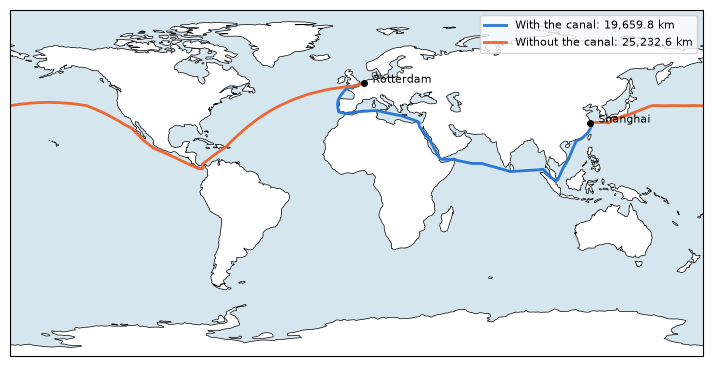

In [5]:
figure = draw_map(
    lines=[
        (route_with_canal["coordinate_path"], "#2a78d6", f"With the canal: {route_with_canal['length']:,.1f} km"),
        (route_without_canal["coordinate_path"], "#eb6834", f"Without the canal: {route_without_canal['length']:,.1f} km"),
    ],
    places=[([31.23, 121.47], "Shanghai"), ([51.95, 4.14], "Rotterdam")],
    coasts="110m",
)
plt.show()

`add_edge(origin_id, destination_id, distance)` adds an arc. The next cell opens the canal again: it adds back each removed arc, with its length.

In [6]:
for (origin, destination), length in removed_arcs.items():
    world_sea.add_edge(origin_id=origin, destination_id=destination, distance=length)

route = world_sea.get_shortest_path(origin_node=SHANGHAI, destination_node=ROTTERDAM)
print(f"Canal open again: {route['length']:,.1f} km")

Canal open again: 19,659.8 km


## 3. Open a canal across Thailand

A ship from Bangkok to India today goes around the Malay Peninsula, through the Strait of Malacca. A canal across Thailand, at the Kra Isthmus, has been proposed many times to shorten this trip.

The canal needs two new nodes, one at each end. `add_coord_node` adds a node at a latitude and a longitude, and returns its id:

- `auto_edge=True` joins the new node to nodes of the network, with arcs in both directions.
- `node_addition_type="closest"` joins it to the nearest node only.
- `mode="sea"` gives the new node the mode `sea`.

`add_haversine_edge` then adds the canal itself: an arc in both directions, whose length is the distance on the globe between the two nodes.

In [7]:
BANGKOK = {"latitude": 13.6, "longitude": 100.6}
CHENNAI = {"latitude": 13.08, "longitude": 80.29}

route_today = world_sea.get_shortest_path(origin_node=BANGKOK, destination_node=CHENNAI)
print(f"Today: {route_today['length']:,.1f} km")

west_end = world_sea.add_coord_node(
    coord_dict={"latitude": 7.4, "longitude": 99.1},  # in the Andaman Sea
    auto_edge=True,
    node_addition_type="closest",
    mode="sea",
)
east_end = world_sea.add_coord_node(
    coord_dict={"latitude": 7.3, "longitude": 100.8},  # in the Gulf of Thailand
    auto_edge=True,
    node_addition_type="closest",
    mode="sea",
)
world_sea.add_haversine_edge(origin_idx=west_end, destination_idx=east_end)

route_with_new_canal = world_sea.get_shortest_path(origin_node=BANGKOK, destination_node=CHENNAI)
print(f"With a canal across Thailand: {route_with_new_canal['length']:,.1f} km")

Today: 4,537.4 km
With a canal across Thailand: 3,256.2 km


The canal would save about 1,300 km on this trip. The new canal is a straight line across the land, in the middle of the map below.

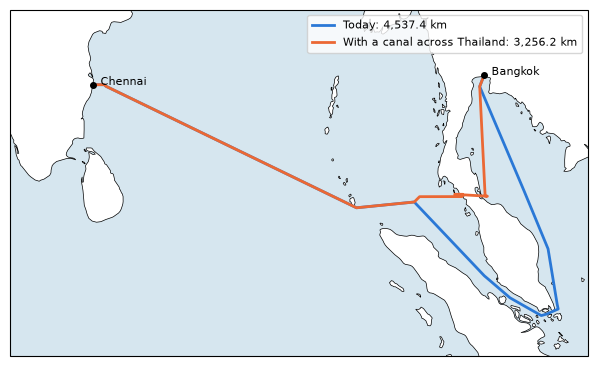

In [8]:
figure = draw_map(
    lines=[
        (route_today["coordinate_path"], "#2a78d6", f"Today: {route_today['length']:,.1f} km"),
        (route_with_new_canal["coordinate_path"], "#eb6834", f"With a canal across Thailand: {route_with_new_canal['length']:,.1f} km"),
    ],
    places=[([13.6, 100.6], "Bangkok"), ([13.08, 80.29], "Chennai")],
    extent=[76, 106, -1, 17],
)
plt.show()

`remove_coord_node` removes the last node that was added, with its arcs. Two calls remove the two ends of the canal, and the canal with them.

In [9]:
world_sea.remove_coord_node()
world_sea.remove_coord_node()

route = world_sea.get_shortest_path(origin_node=BANGKOK, destination_node=CHENNAI)
print(f"Without the new canal: {route['length']:,.1f} km, and {len(world_sea.nodes):,} nodes")

Without the new canal: 4,537.4 km, and 43,233 nodes


## 4. Save a changed network

A change lives in memory only. The next `load_geograph("world_sea")` loads the network as it was published. To keep a changed network, save it to a file with `save_as_scgraph`, and load it later with `load_from_scgraph`.

The next cell closes the Suez Canal again, saves the network to a file in the current folder, and loads the file.

In [10]:
for origin, destination in removed_arcs:
    world_sea.remove_edge(origin_id=origin, destination_id=destination)
world_sea.save_as_scgraph("world_sea_without_suez.scgraph")

without_suez = GeoGraph.load_from_scgraph("world_sea_without_suez.scgraph")
route = without_suez.get_shortest_path(origin_node=SHANGHAI, destination_node=ROTTERDAM)
print(f"Shanghai to Rotterdam on the saved network: {route['length']:,.1f} km")

Shanghai to Rotterdam on the saved network: 25,232.6 km


`save_as_geojson` writes the network as a GeoJSON file, which a tool such as [geojson.io](https://geojson.io) shows on a map. It helps to find the nodes to change.

## What to remember

- `remove_edge` and `add_edge` remove and add an arc between two nodes, by their ids.
- `add_coord_node` adds a node at a latitude and a longitude. `remove_coord_node` removes the last added node.
- `add_haversine_edge` adds an arc whose length is the distance on the globe between two nodes.
- Find the ids of the nodes from their coordinates. The ids can change from one version of a network to the next.
- `save_as_scgraph` keeps a changed network in a file.